# 03 · Build the features

**Goal.** For every study square and season, collect the things that could explain *why* it flooded more or less than usual: rain, terrain, and rivers. Then join them to the labels as **the model table**.

**Inputs.** `data_small/labels.parquet` (notebook 02), the CHIRPS daily rain (1 May to 21 Oct, three seasons), HydroSHEDS rivers and basins, and the Copernicus 30 m DEM from Planetary Computer.
**Outputs.**
- `data_small/model_table.parquet`: **one row per square and season**, label plus features. Notebook 04 starts here.
- `results/feature_dictionary.csv`: what each feature means, for the paper
- `figures/fig_features_maps.png`

**The features**

| group | features | physical idea |
|---|---|---|
| Rain at the square (per season) | `rain_early`, `rain_window`, `rain_aug`, `rain_sep`, `rain_oct`, `max_1d`, `max_3d`, `max_7d`, `heavy_days` | more and more intense rain → more water to drain |
| Rain upstream (per season) | `up_rain_window`, `up_rain_early`, `up_coverage` | floods often come from rain that fell far upstream |
| Terrain (fixed) | `elev_mean`, `elev_p05`, `elev_std`, `slope_mean`, `rel_height`, `low_share` | low, flat ground holds water; steep ground sheds it |
| Rivers (fixed) | `dist_riv_any_km`, `dist_riv_1k_km`, `dist_riv_10k_km`, `log_upland_nearest`, `log_up_area` | squares near big rivers overflow first |
| Groups (not inputs) | `basin_l4`, `basin_l5`, `basin_l6` | the regions held out together in validation |

**Two rules for honest features** (Week 6: *would I have this number when the prediction is made?*):
- Every rain feature ends on **21 October**, the last day of the flood window. This is a **seasonal analysis** that explains a season after its rain has fallen, as stated in the proposal. It is not a forecast.
- **Flood history** (how much a square usually floods) is built **in notebook 04, inside each validation split**, from the training seasons only. Building it here would let the test season leak into its own inputs.

**Steps**
1. Load the labels and the grid
2. Rain at each square
3. Rain upstream (HydroBASINS)
4. Distance to rivers (HydroRIVERS)
5. Terrain (Copernicus DEM)
6. Join everything into the model table
7. First physical sanity check

## Setup

In [1]:
import sys, re, warnings
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from config import *

import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
from src.flood_utils import savefig

warnings.filterwarnings("ignore")
UTM = "EPSG:32647"                       # metres; fine for distances across Thailand

## Step 1 · Load the labels and the grid

The labels already carry each square's `row` and `col` on the 5 km CHIRPS grid. Every feature below is first computed as a map on that grid, then read off at those positions.

In [2]:
labels = pd.read_parquet(SMALL_DIR / "labels.parquet")
cells = labels[labels.season == YEARS[0]][["cell_id", "row", "col", "lat", "lon"]].reset_index(drop=True)

with rasterio.open(sorted(RAW_CHIRPS.glob("*.tif"))[0]) as src:
    T_GRID = src.transform                     # 5 km grid: x = c + col*0.05, y = f - row*0.05
    H, W = src.height, src.width
grid_x = T_GRID.c + (np.arange(W) + 0.5) * T_GRID.a     # square centres
grid_y = T_GRID.f + (np.arange(H) + 0.5) * T_GRID.e

R_, C_ = cells.row.values, cells.col.values
def at_cells(a):
    """Read a (H, W) map at the study squares."""
    return a[R_, C_]

print(len(cells), "study squares |", labels.shape[0], "label rows | grid", H, "x", W)

3974 study squares | 11922 label rows | grid 299 x 169


## Step 2 · Rain at each square

We stack all 522 daily rain maps into one array (day × row × col) and save it for reuse. Then, for each season:

- `rain_early`: 1 May to 3 Aug, before the window. Wet soil and full reservoirs make later floods easier.
- `rain_window`: 4 Aug to 21 Oct, the flood window itself
- `rain_aug`, `rain_sep`, `rain_oct`: monthly totals (October = 1 to 21)
- `max_1d`, `max_3d`, `max_7d`: the wettest 1-, 3- and 7-day spells **ending inside the window**
- `heavy_days`: days in the window with at least 20 mm

In [3]:
def date_of(p):
    m = re.search(r"(20\d{2})[._-]?(\d{2})[._-]?(\d{2})", p.name)
    return pd.Timestamp(int(m[1]), int(m[2]), int(m[3]))

stack_file = INTERIM / "chirps_may_oct_stack.npz"
if stack_file.exists():
    z = np.load(stack_file, allow_pickle=True)
    RAIN, DATES = z["rain"], pd.DatetimeIndex(z["dates"])
else:
    files = sorted(RAW_CHIRPS.glob("*.tif"), key=date_of)
    arrs = []
    for f in files:
        with rasterio.open(f) as src:
            a = src.read(1, masked=True).filled(np.nan).astype("float32")
        arrs.append(np.where(a < 0, np.nan, a))
    RAIN, DATES = np.stack(arrs), pd.DatetimeIndex([date_of(f) for f in files])
    np.savez_compressed(stack_file, rain=RAIN, dates=DATES.values)

print("rain stack:", RAIN.shape, "| days per season:", pd.Series(DATES.year).value_counts().sort_index().to_dict())

rain stack: (522, 299, 169) | days per season: {2024: 174, 2025: 174, 2026: 174}


**What to check:** shape (522, 299, 169), and 174 days in each season.

In [4]:
def max_k_day(r, end_ok, k):
    """Largest k-day rain total among spells that END on a day where end_ok is True."""
    cs = np.concatenate([np.zeros((1,) + r.shape[1:], "float32"), np.cumsum(r, axis=0)])
    sums = cs[k:] - cs[:-k]                  # sums[i] = rain on days i .. i+k-1
    return sums[end_ok[k - 1:]].max(axis=0)

rain_maps = {}
for y in YEARS:
    sel = DATES.year == y
    r, d = RAIN[sel], DATES[sel]
    md_ = d.strftime("%m-%d")
    win = (md_ >= FLOOD_WINDOW[0]) & (md_ <= FLOOD_WINDOW[1])
    rain_maps[y] = {
        "rain_early":  r[md_ < FLOOD_WINDOW[0]].sum(0),
        "rain_window": r[win].sum(0),
        "rain_aug":    r[d.month == 8].sum(0),
        "rain_sep":    r[d.month == 9].sum(0),
        "rain_oct":    r[d.month == 10].sum(0),
        "max_1d":      max_k_day(r, win, 1),
        "max_3d":      max_k_day(r, win, 3),
        "max_7d":      max_k_day(r, win, 7),
        "heavy_days":  (r[win] >= 20).sum(0).astype("float32"),
    }

summary = pd.DataFrame({y: {k: float(np.nanmean(at_cells(v))) for k, v in rain_maps[y].items()} for y in YEARS}).round(0)
summary

,2024,2025,2026
rain_early,781.0,800.0,602.0
rain_window,683.0,682.0,531.0
rain_aug,294.0,279.0,238.0
rain_sep,352.0,321.0,276.0
rain_oct,70.0,86.0,51.0
max_1d,60.0,53.0,48.0
max_3d,97.0,85.0,86.0
max_7d,148.0,142.0,138.0
heavy_days,12.0,10.0,8.0


**What to check:** the study-area averages look like Thai monsoon numbers (window totals of several hundred mm, wettest day a few tens of mm), and 2026 is the driest season, as found in October.

## Step 3 · Rain upstream

A square on the Chao Phraya can flood from rain that fell 300 km north, on the Ping or the Nan. HydroBASINS splits the land into small basins (level 8), and each basin knows which basin it drains into. We work out the average rain of each basin, then pass it downstream, from the smallest catchments to the largest, so each basin ends up holding the **area-weighted average rain of everything that drains through it**. An analogy: buckets pouring into each other along the river.

`up_coverage` is the share of the upstream area that has rain data. The rain maps cover Thailand, so squares on the Mekong, whose upstream area is mostly in Laos and China, get a low coverage. Their upstream rain is incomplete, and the model can know it.

In [5]:
box = (float(grid_x.min()), float(grid_y.min()), float(grid_x.max()), float(grid_y.max()))
basin_file = lambda lev: next((RAW_HYDRO / "basins").rglob(f"*lev{lev:02d}*.shp"))
hb = {lev: gpd.read_file(basin_file(lev), bbox=box) for lev in (4, 5, 6, 8)}
for lev, g in hb.items():
    print(f"level {lev}: {len(g)} basins")

b8 = hb[8].set_index("HYBAS_ID")[["NEXT_DOWN", "SUB_AREA", "UP_AREA"]]

# which level-8 basin each 5 km pixel centre falls in
GX, GY = np.meshgrid(grid_x, grid_y)
pix = gpd.GeoDataFrame({"pix": np.arange(GX.size)}, geometry=gpd.points_from_xy(GX.ravel(), GY.ravel()), crs="EPSG:4326")
pix = gpd.sjoin(pix, hb[8][["HYBAS_ID", "geometry"]], how="inner", predicate="within").drop_duplicates("pix")
pix_basin = pd.Series(pix["HYBAS_ID"].values, index=pix["pix"].values)

# which basin each study square sits in (all four levels)
pts = gpd.GeoDataFrame(cells[["cell_id"]], geometry=gpd.points_from_xy(cells.lon, cells.lat), crs="EPSG:4326")
for lev in (4, 5, 6, 8):
    j = gpd.sjoin(pts, hb[lev][["HYBAS_ID", "geometry"]], how="left", predicate="within").drop_duplicates("cell_id")
    cells[f"basin_l{lev}"] = j.set_index("cell_id")["HYBAS_ID"].reindex(cells.cell_id).astype("Int64").values
print("study squares without a basin:", int(cells.basin_l8.isna().sum()))

level 4: 16 basins
level 5: 59 basins
level 6: 123 basins
level 8: 1480 basins
study squares without a basin: 0


In [6]:
def upstream_mean(field2d):
    """Area-weighted mean of a (H, W) field over everything upstream of each level-8 basin."""
    vals = field2d.ravel()[pix_basin.index.values]
    basin_val = pd.Series(vals).groupby(pix_basin.values).mean()
    t = b8.sort_values("UP_AREA")                                  # small catchments first
    v = basin_val.reindex(t.index)
    w = (v * t.SUB_AREA).fillna(0).to_dict()                       # mm x km2
    a = t.SUB_AREA.where(v.notna(), 0).to_dict()                   # km2 with data
    for hid, nd in zip(t.index, t.NEXT_DOWN):
        if nd in w:                                                # pass downstream
            w[nd] += w[hid]; a[nd] += a[hid]
    w, a = pd.Series(w), pd.Series(a)
    return w / a.replace(0, np.nan), (a / t.UP_AREA).clip(upper=1)

up_feats = {}
for y in YEARS:
    up_win, coverage = upstream_mean(rain_maps[y]["rain_window"])
    up_early, _ = upstream_mean(rain_maps[y]["rain_early"])
    up_feats[y] = {"up_rain_window": cells.basin_l8.map(up_win).astype(float).values,
                   "up_rain_early":  cells.basin_l8.map(up_early).astype(float).values,
                   "up_coverage":    cells.basin_l8.map(coverage).astype(float).values}
cells["log_up_area"] = np.log10(cells.basin_l8.map(b8.UP_AREA).astype(float))

print(pd.Series(up_feats[2025]["up_coverage"]).describe().round(2).to_string())

count    3974.00
mean        0.98
std         0.11
min         0.12
25%         1.00
50%         1.00
75%         1.00
max         1.00


**What to check:** coverage is 1.0 for most squares (Chao Phraya, Chi and Mun are inside Thailand) and lower only for a minority near the Mekong. Every square has a basin.

## Step 4 · Distance to rivers

For each square centre, the distance to the nearest river of three sizes (by upstream area): any river in HydroRIVERS (≥ 10 km²), medium (≥ 1,000 km²) and big (≥ 10,000 km², e.g. the Chao Phraya, Mun, Chi and Mekong). Distances are measured in metres in a UTM projection, then converted to km. We also keep the size of the nearest river.

In [7]:
pad = 1.0
study_box = (cells.lon.min() - pad, cells.lat.min() - pad, cells.lon.max() + pad, cells.lat.max() + pad)
riv = gpd.read_file(next((RAW_HYDRO / "rivers").rglob("*.shp")), bbox=study_box)[["UPLAND_SKM", "geometry"]].to_crs(UTM)
pts_m = pts.to_crs(UTM)
print(len(riv), "river reaches near the study area")

for label, min_up in [("any", 0), ("1k", 1_000), ("10k", 10_000)]:
    j = gpd.sjoin_nearest(pts_m, riv[riv.UPLAND_SKM >= min_up], how="left", distance_col="d")
    j = j.drop_duplicates("cell_id").set_index("cell_id")
    cells[f"dist_riv_{label}_km"] = (j["d"] / 1000).reindex(cells.cell_id).values
    if label == "any":
        cells["log_upland_nearest"] = np.log10(j["UPLAND_SKM"].reindex(cells.cell_id).values)

cells.filter(like="dist_riv").describe().round(1)

47555 river reaches near the study area


,dist_riv_any_km,dist_riv_1k_km,dist_riv_10k_km
count,3974.0,3974.0,3974.0
mean,1.3,12.4,37.0
std,0.9,9.0,27.2
min,0.0,0.0,0.0
25%,0.6,4.8,13.9
50%,1.1,10.8,32.7
75%,1.8,18.6,54.8
max,5.1,40.3,121.3


**What to check:** distances to any river are small (a few km at most), and to big rivers range from 0 to tens of km.

## Step 5 · Terrain from the Copernicus DEM

We load the 30 m Copernicus elevation model, averaged to about 110 m (0.001°), on a grid that lines up **exactly** with the 5 km squares (50 × 50 DEM pixels per square). Per square we compute:

- `elev_mean`, `elev_p05` (the lowest 5% of the square), `elev_std` (how hilly), `slope_mean` (degrees)
- `low_share`: share of the square within 2 m of its own lowest 5%, i.e. how much of it is flat valley floor
- `rel_height`: how far the square's average sits above the lowest ground within about 12 km (the lowest `elev_p05` in the surrounding 5 × 5 squares). This is a simple version of "height above the nearest drainage".

The download is a few hundred MB and runs once; the results are saved.

In [8]:
terrain_file = INTERIM / "terrain_5km.parquet"
SUB = int(round(GRID_RES_DEG / 0.001))                 # 50 DEM pixels per square side

if terrain_file.exists():
    terrain = pd.read_parquet(terrain_file)
    print("loaded saved terrain")
else:
    import pystac_client, planetary_computer, odc.stac
    from odc.geo.geobox import GeoBox
    from affine import Affine
    from scipy.ndimage import minimum_filter

    m = 3                                               # extra squares around the study area, for rel_height
    r0, r1 = max(R_.min() - m, 0), min(R_.max() + m, H - 1)
    c0, c1 = max(C_.min() - m, 0), min(C_.max() + m, W - 1)
    nr, nc = r1 - r0 + 1, c1 - c0 + 1
    x0, y0 = T_GRID.c + c0 * T_GRID.a, T_GRID.f + r0 * T_GRID.e
    gbox = GeoBox((nr * SUB, nc * SUB), Affine(0.001, 0, x0, 0, -0.001, y0), "EPSG:4326")

    catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                        modifier=planetary_computer.sign_inplace)
    items = catalog.search(collections=["cop-dem-glo-30"], bbox=list(gbox.boundingbox)).item_collection()
    print("DEM tiles:", len(items), "| grid:", gbox.shape)
    dem = odc.stac.load(items, bands=["data"], geobox=gbox, resampling="average",
                        chunks={"x": 2048, "y": 2048}).compute()["data"].squeeze().values.astype("float32")
    dem[dem < -100] = np.nan                            # 'no data' values, if any

    # slope, one strip of squares at a time to save memory
    lat_mid = np.deg2rad(y0 - nr * GRID_RES_DEG / 2)
    dy, dx = 0.001 * 111_320, 0.001 * 111_320 * np.cos(lat_mid)
    slope = np.empty_like(dem)
    for i in range(nr):
        a, b = max(i * SUB - 1, 0), min((i + 1) * SUB + 1, dem.shape[0])
        gy, gx = np.gradient(dem[a:b], dy, dx)
        s = np.degrees(np.arctan(np.hypot(gx, gy)))
        slope[i * SUB:(i + 1) * SUB] = s[(i * SUB - a):(i * SUB - a) + SUB]

    blocks = lambda a: a.reshape(nr, SUB, nc, SUB).transpose(0, 2, 1, 3).reshape(nr, nc, SUB * SUB)
    B, S = blocks(dem), blocks(slope)
    p05 = np.nanpercentile(B, 5, axis=2)
    stats = {"elev_mean": np.nanmean(B, 2), "elev_p05": p05, "elev_std": np.nanstd(B, 2), "slope_mean": np.nanmean(S, 2),
             "low_share": (B <= p05[..., None] + 2).mean(2)}
    stats["rel_height"] = stats["elev_mean"] - minimum_filter(np.nan_to_num(p05, nan=1e4), size=5, mode="nearest")

    terrain = pd.DataFrame({"cell_id": cells.cell_id})
    for k, v in stats.items():
        terrain[k] = v[R_ - r0, C_ - c0]
    terrain.to_parquet(terrain_file, index=False)
    del dem, slope, B, S

cells = cells.merge(terrain, on="cell_id")
cells[["elev_mean", "elev_p05", "elev_std", "slope_mean", "low_share", "rel_height"]].describe().round(2)

DEM tiles: 42 | grid: Shape2d(x=5250, y=6100)


,elev_mean,elev_p05,elev_std,slope_mean,low_share,rel_height
count,3974.00,3974.00,3974.00,3974.00,3974.00,3974.00
mean,209.29,174.18,27.25,2.57,0.23,77.66
std,183.67,141.30,43.66,3.55,0.22,143.09
min,3.35,1.79,0.35,0.03,0.05,0.65
25%,129.16,98.79,4.62,0.60,0.09,10.92
50%,174.07,161.62,8.00,1.07,0.12,24.79
75%,224.30,195.55,28.49,2.63,0.28,58.66
max,1536.62,1297.33,344.29,23.07,1.00,1380.64


**What to check:** the central plain sits at a few tens of metres and the Khorat Plateau (northeast) at roughly 100 to 200 m. Slopes are small (mostly under a few degrees), and nothing is missing.

## Step 6 · Join everything into the model table

Fixed features (terrain, rivers, basins) are the same in all seasons. Rain features change by season. The result has one row per square and season, with the label columns from notebook 02 and every feature.

In [9]:
rain_cols = list(rain_maps[YEARS[0]].keys())
up_cols = ["up_rain_window", "up_rain_early", "up_coverage"]

parts = []
for y in YEARS:
    t = pd.DataFrame({"cell_id": cells.cell_id, "season": y})
    for k in rain_cols:
        t[k] = at_cells(rain_maps[y][k])
    for k in up_cols:
        t[k] = up_feats[y][k]
    parts.append(t)
season_feats = pd.concat(parts, ignore_index=True)

static_cols = ["log_up_area", "dist_riv_any_km", "dist_riv_1k_km", "dist_riv_10k_km", "log_upland_nearest",
               "elev_mean", "elev_p05", "elev_std", "slope_mean", "low_share", "rel_height",
               "basin_l4", "basin_l5", "basin_l6", "basin_l8"]
table = (labels.merge(season_feats, on=["cell_id", "season"])
               .merge(cells[["cell_id"] + static_cols], on="cell_id"))

FEATURES = rain_cols + up_cols + static_cols[:11]
print(table.shape, "| features:", len(FEATURES))
print("missing values per feature (should be 0, except possibly upstream rain):")
print(table[FEATURES].isna().sum()[lambda s: s > 0].to_string() or "none")

table.to_parquet(SMALL_DIR / "model_table.parquet", index=False)
print("saved", SMALL_DIR / "model_table.parquet")

(11922, 38) | features: 23
missing values per feature (should be 0, except possibly upstream rain):
Series([], )
saved /home/tb3203/thailand-flood-ml/data_small/model_table.parquet


**What to check:** 11,922 rows and 23 features, with no missing values (a handful in upstream rain is acceptable; notebook 04 will deal with it).

In [10]:
desc = {
 "rain_early": "Rain at the square, 1 May to 3 Aug (mm)", "rain_window": "Rain at the square, 4 Aug to 21 Oct (mm)",
 "rain_aug": "August rain (mm)", "rain_sep": "September rain (mm)", "rain_oct": "Rain 1 to 21 Oct (mm)",
 "max_1d": "Wettest day in the window (mm)", "max_3d": "Wettest 3 days ending in the window (mm)",
 "max_7d": "Wettest 7 days ending in the window (mm)", "heavy_days": "Days in the window with at least 20 mm",
 "up_rain_window": "Area-weighted rain over everything upstream, window (mm)",
 "up_rain_early": "Area-weighted rain over everything upstream, 1 May to 3 Aug (mm)",
 "up_coverage": "Share of the upstream area inside the rain data (0 to 1)",
 "log_up_area": "log10 of the area draining through the square's basin (km2)",
 "dist_riv_any_km": "Distance to the nearest river (km)", "dist_riv_1k_km": "Distance to a river draining at least 1,000 km2 (km)",
 "dist_riv_10k_km": "Distance to a river draining at least 10,000 km2 (km)",
 "log_upland_nearest": "log10 upstream area of the nearest river (km2)",
 "elev_mean": "Mean elevation (m)", "elev_p05": "Elevation of the lowest 5% of the square (m)",
 "elev_std": "Standard deviation of elevation within the square (m)", "slope_mean": "Mean slope (degrees)",
 "low_share": "Share of the square within 2 m of its lowest 5%", "rel_height": "Mean elevation minus the lowest ground within about 12 km (m)",
}
group = lambda f: ("rain (square)" if f in rain_cols else "rain (upstream)" if f in up_cols else
                   "rivers" if ("riv" in f or "up_area" in f or "upland" in f) else "terrain")
fd = pd.DataFrame({"feature": FEATURES, "group": [group(f) for f in FEATURES], "meaning": [desc[f] for f in FEATURES]})
fd.to_csv(RESULTS_DIR / "feature_dictionary.csv", index=False)
fd

,feature,group,meaning
0,rain_early,rain (square),"Rain at the square, 1 May to 3 Aug (mm)"
1,rain_window,rain (square),"Rain at the square, 4 Aug to 21 Oct (mm)"
2,rain_aug,rain (square),August rain (mm)
3,rain_sep,rain (square),September rain (mm)
4,rain_oct,rain (square),Rain 1 to 21 Oct (mm)
5,max_1d,rain (square),Wettest day in the window (mm)
6,max_3d,rain (square),Wettest 3 days ending in the window (mm)
7,max_7d,rain (square),Wettest 7 days ending in the window (mm)
8,heavy_days,rain (square),Days in the window with at least 20 mm
9,up_rain_window,rain (upstream),"Area-weighted rain over everything upstream, w..."


## Step 7 · First physical sanity check

Before any model, does each feature move with flooding in the direction physics says? We use the **Spearman rank correlation**, which only asks "when this goes up, does flooding tend to go up?" and isn't thrown off by the many zeros. Expected signs: rain **+**, distance to rivers **−**, elevation, slope and relative height **−**, low flat share **+**.

This is only a first look. Correlations can't untangle features that move together (for example, low ground is usually near big rivers). The model and the permutation importance in notebook 04 do that properly.

In [11]:
expected = {"rain_": "+", "max_": "+", "heavy": "+", "up_rain": "+", "up_cov": "?", "log_up": "+", "dist_": "-",
            "log_upland": "+", "elev_": "-", "slope": "-", "rel_height": "-", "low_share": "+"}
def exp_sign(f):
    return next((s for k, s in expected.items() if f.startswith(k)), "?")

rho = pd.DataFrame({"pooled": table[FEATURES].corrwith(table.flooded_frac, method="spearman")})
for y in YEARS:
    t = table[table.season == y]
    rho[y] = t[FEATURES].corrwith(t.flooded_frac, method="spearman")
rho["expected"] = [exp_sign(f) for f in FEATURES]
rho = rho.round(2).sort_values("pooled")
rho

,pooled,2024,2025,2026,expected
rel_height,-0.54,-0.53,-0.56,-0.53,-
dist_riv_1k_km,-0.46,-0.48,-0.51,-0.39,-
elev_std,-0.44,-0.43,-0.44,-0.46,-
elev_mean,-0.43,-0.38,-0.40,-0.53,-
slope_mean,-0.42,-0.40,-0.43,-0.45,-
elev_p05,-0.40,-0.35,-0.36,-0.52,-
dist_riv_10k_km,-0.34,-0.35,-0.32,-0.38,-
dist_riv_any_km,-0.10,-0.12,-0.14,-0.04,-
rain_early,-0.07,-0.04,-0.03,-0.30,+
up_coverage,-0.05,-0.04,-0.02,-0.07,?


**What to check:** terrain and river distances should show clear negative values and be stable across seasons. Rain at the square may be **weak or even negative**: much of the flooding on the central plain comes from upstream rain, not local rain. If so, that is a real finding to discuss, not a bug.

saved /home/tb3203/thailand-flood-ml/figures/fig_features_maps.png


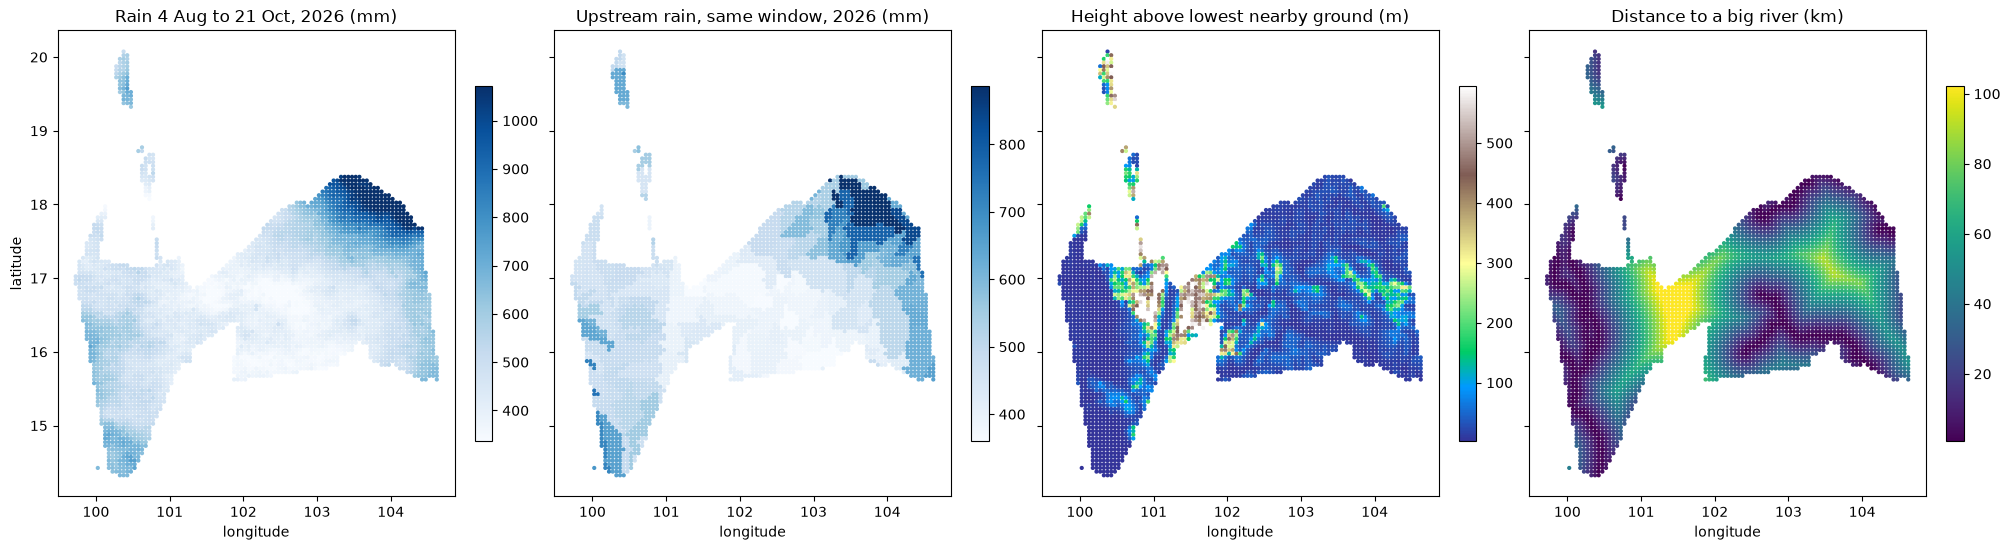

In [12]:
show = [("rain_window", "Rain 4 Aug to 21 Oct, 2026 (mm)", "Blues", 2026),
        ("up_rain_window", "Upstream rain, same window, 2026 (mm)", "Blues", 2026),
        ("rel_height", "Height above lowest nearby ground (m)", "terrain", None),
        ("dist_riv_10k_km", "Distance to a big river (km)", "viridis", None)]
fig, ax = plt.subplots(1, 4, figsize=(20, 6), sharey=True, layout="constrained")
for a, (col, title, cmap, yr) in zip(ax, show):
    t = table[table.season == (yr or YEARS[0])]
    v = t[col]
    sc = a.scatter(t.lon, t.lat, c=v, s=4, cmap=cmap, vmin=v.quantile(0.02), vmax=v.quantile(0.98))
    a.set_title(title); a.set_aspect("equal"); a.set_xlabel("longitude")
    fig.colorbar(sc, ax=a, shrink=0.6)
ax[0].set_ylabel("latitude")
savefig(fig, "fig_features_maps", FIG_DIR)
plt.show()

**What to check:** rain is highest near the eastern and northern edges, upstream rain is smoother along the river valleys, relative height is lowest on the central plain and along river valleys, and the big-river distance is zero along the Chao Phraya, Mun, Chi and Mekong.

## Summary

`data_small/model_table.parquet` now holds everything the modelling needs: one row per square and season, the label (plus its 1-pass and raw versions for sensitivity tests), 23 features, and the basin groups for validation. From here on, notebook 04 runs from this small file alone.

**Save the work** (in a terminal):
```bash
cd ~/thailand-flood-ml
git add -A
git commit -m "Notebook 03: rain, upstream rain, river and terrain features; model table"
git push
```
Next: `04_main_analysis.ipynb`: baselines, models, validation, uncertainty and interpretation.